# 📡 Predictive Customer Churn Classifier
## Random Forest & XGBoost | SMOTE | ROC-AUC | Telco Dataset

**Goal:** Predict customer churn using ensemble ML models, handle severe class imbalance with SMOTE, and achieve ROC-AUC > 80%.  
**Dataset:** IBM Telco Customer Churn (7,043 records, 21 features)

---

## 📦 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path

# Scikit-Learn
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc,
    ConfusionMatrixDisplay, average_precision_score,
    precision_recall_curve
)

# Imbalanced-learn (SMOTE)
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    SMOTE_AVAILABLE = True
    print('✅ imbalanced-learn available — SMOTE will be used')
except ImportError:
    SMOTE_AVAILABLE = False
    print('⚠️  imbalanced-learn not found — using class_weight="balanced" instead')
    print('   Install with: pip install imbalanced-learn')

# XGBoost
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
    print('✅ XGBoost available')
except ImportError:
    XGBOOST_AVAILABLE = False
    print('⚠️  XGBoost not found — install with: pip install xgboost')

PROJECT_DIR_CANDIDATES = []
for base_dir in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    PROJECT_DIR_CANDIDATES.extend(
        [
            base_dir,
            base_dir / "Task3_CustomerChurn_Classifier",
            base_dir / "task-3-customer-churn-classification",
            base_dir / "datheon-machine-learning-internship" / "task-3-customer-churn-classification",
        ]
    )
PROJECT_DIR = next(
    (candidate for candidate in PROJECT_DIR_CANDIDATES
     if (candidate / "Telco-Customer-Churn.csv").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not locate Telco-Customer-Churn.csv. Run this notebook from a Task 3 project folder."
    )
CSV_PATH = PROJECT_DIR / "Telco-Customer-Churn.csv"
FIGURES_DIR = PROJECT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project directory: {PROJECT_DIR}")
print(f"Generated plots will be saved in: {FIGURES_DIR}")

# Plot style
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

RANDOM_STATE = 42
print('\n✅ All libraries imported!')

✅ imbalanced-learn available — SMOTE will be used
✅ XGBoost available
Project directory: C:\Users\rainc\Downloads\Projects(intern)\Projects(intern)\Datheon\Task3_CustomerChurn_Classifier
Generated plots will be saved in: C:\Users\rainc\Downloads\Projects(intern)\Projects(intern)\Datheon\Task3_CustomerChurn_Classifier\figures

✅ All libraries imported!


## 📂 2. Load Dataset

In [2]:
df = pd.read_csv(CSV_PATH)
print(f'Loaded local dataset: {CSV_PATH}')
print(f'Shape: {df.shape}')
df.head()

Loaded local dataset: C:\Users\rainc\Downloads\Projects(intern)\Projects(intern)\Datheon\Task3_CustomerChurn_Classifier\Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 🔍 3. Exploratory Data Analysis

In [3]:
print('📊 Dataset Info:')
df.info()
print('\n📈 Descriptive Statistics (numeric):')
df.describe().T

📊 Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


Churn Distribution:
  No: 5,174 (73.5%)
  Yes: 1,869 (26.5%)
  Imbalance Ratio: 2.8:1


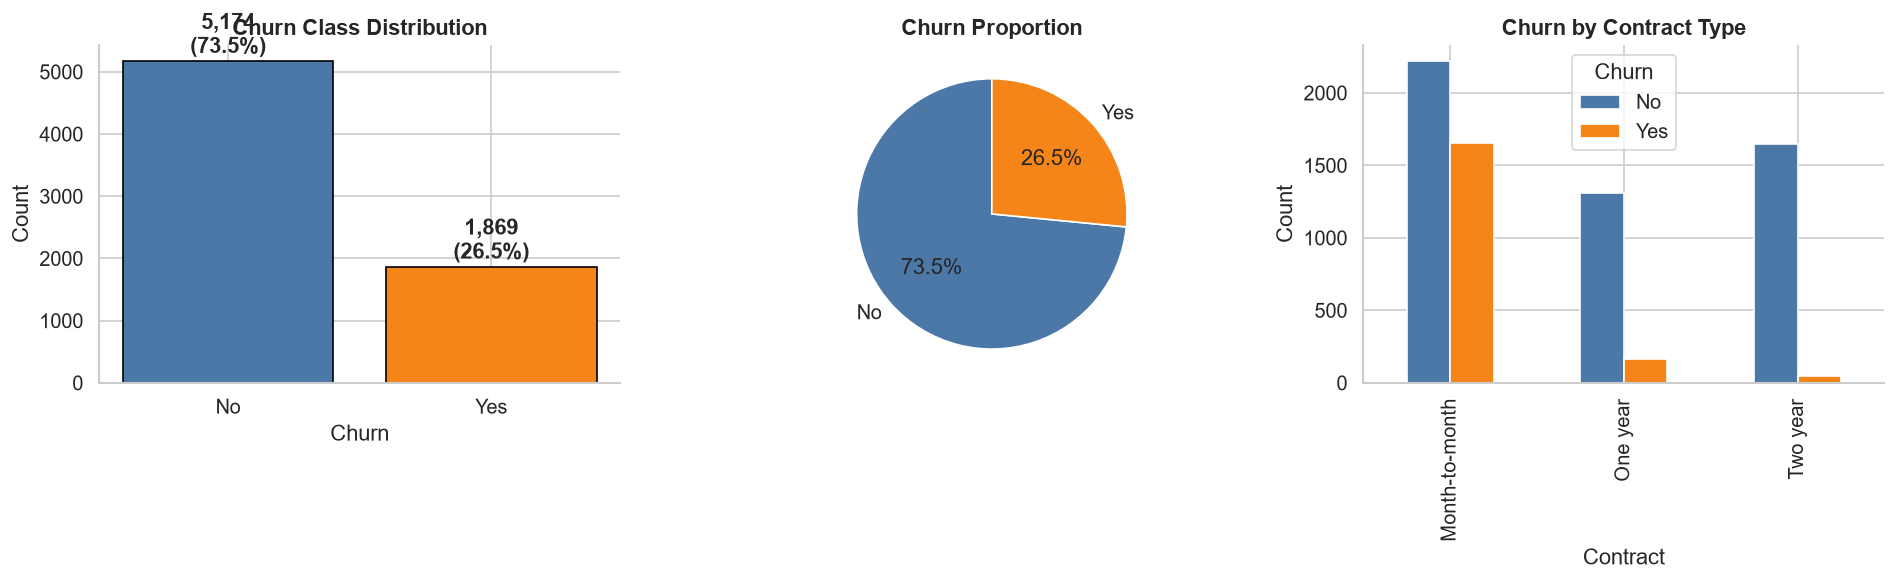

In [4]:
# ?? Target Class Distribution ????????????????????????????????????????????????
churn_counts = df['Churn'].value_counts()
churn_pct    = df['Churn'].value_counts(normalize=True) * 100

print('Churn Distribution:')
for k in churn_counts.index:
    print(f'  {k}: {churn_counts[k]:,} ({churn_pct[k]:.1f}%)')

labels = list(churn_counts.index)
majority = labels[0]
minority = labels[1] if len(labels) > 1 else labels[0]
print(f'  Imbalance Ratio: {churn_counts[majority] / churn_counts[minority]:.1f}:1')

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Bar chart
axes[0].bar(churn_counts.index, churn_counts.values, color=['#4C78A8', '#F58518'], edgecolor='black')
axes[0].set_title('Churn Class Distribution', fontweight='bold')
axes[0].set_xlabel('Churn')
axes[0].set_ylabel('Count')

for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 30, f'{v:,}\n({churn_pct[churn_counts.index[i]]:.1f}%)', ha='center', va='bottom', fontweight='bold')

# Pie chart
axes[1].pie(churn_counts.values, labels=churn_counts.index, autopct='%1.1f%%', startangle=90, colors=['#4C78A8', '#F58518'])
axes[1].set_title('Churn Proportion', fontweight='bold')

# Contract churn comparison
contract_churn = df.groupby('Contract')['Churn'].value_counts().unstack(fill_value=0)
contract_churn = contract_churn.reindex(['Month-to-month', 'One year', 'Two year'], fill_value=0)
contract_churn.plot(kind='bar', ax=axes[2], color=['#4C78A8', '#F58518'])
axes[2].set_title('Churn by Contract Type', fontweight='bold')
axes[2].set_xlabel('Contract')
axes[2].set_ylabel('Count')
axes[2].legend(title='Churn')

plt.tight_layout()
plt.show()


In [ ]:
# ── Numerical Feature Distributions by Churn ─────────────────────────────────
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
colors = {'No': '#5B84B1', 'Yes': '#E07B54'}

for ax, col in zip(axes, num_cols):
    for churn_val, color in colors.items():
        subset = df[df['Churn'] == churn_val][col].dropna()
        ax.hist(subset, bins=40, alpha=0.6, color=color,
                edgecolor='none', label=f'Churn={churn_val}', density=True)
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('Numerical Features by Churn Status', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_numeric_distributions.png', bbox_inches='tight')
plt.show()

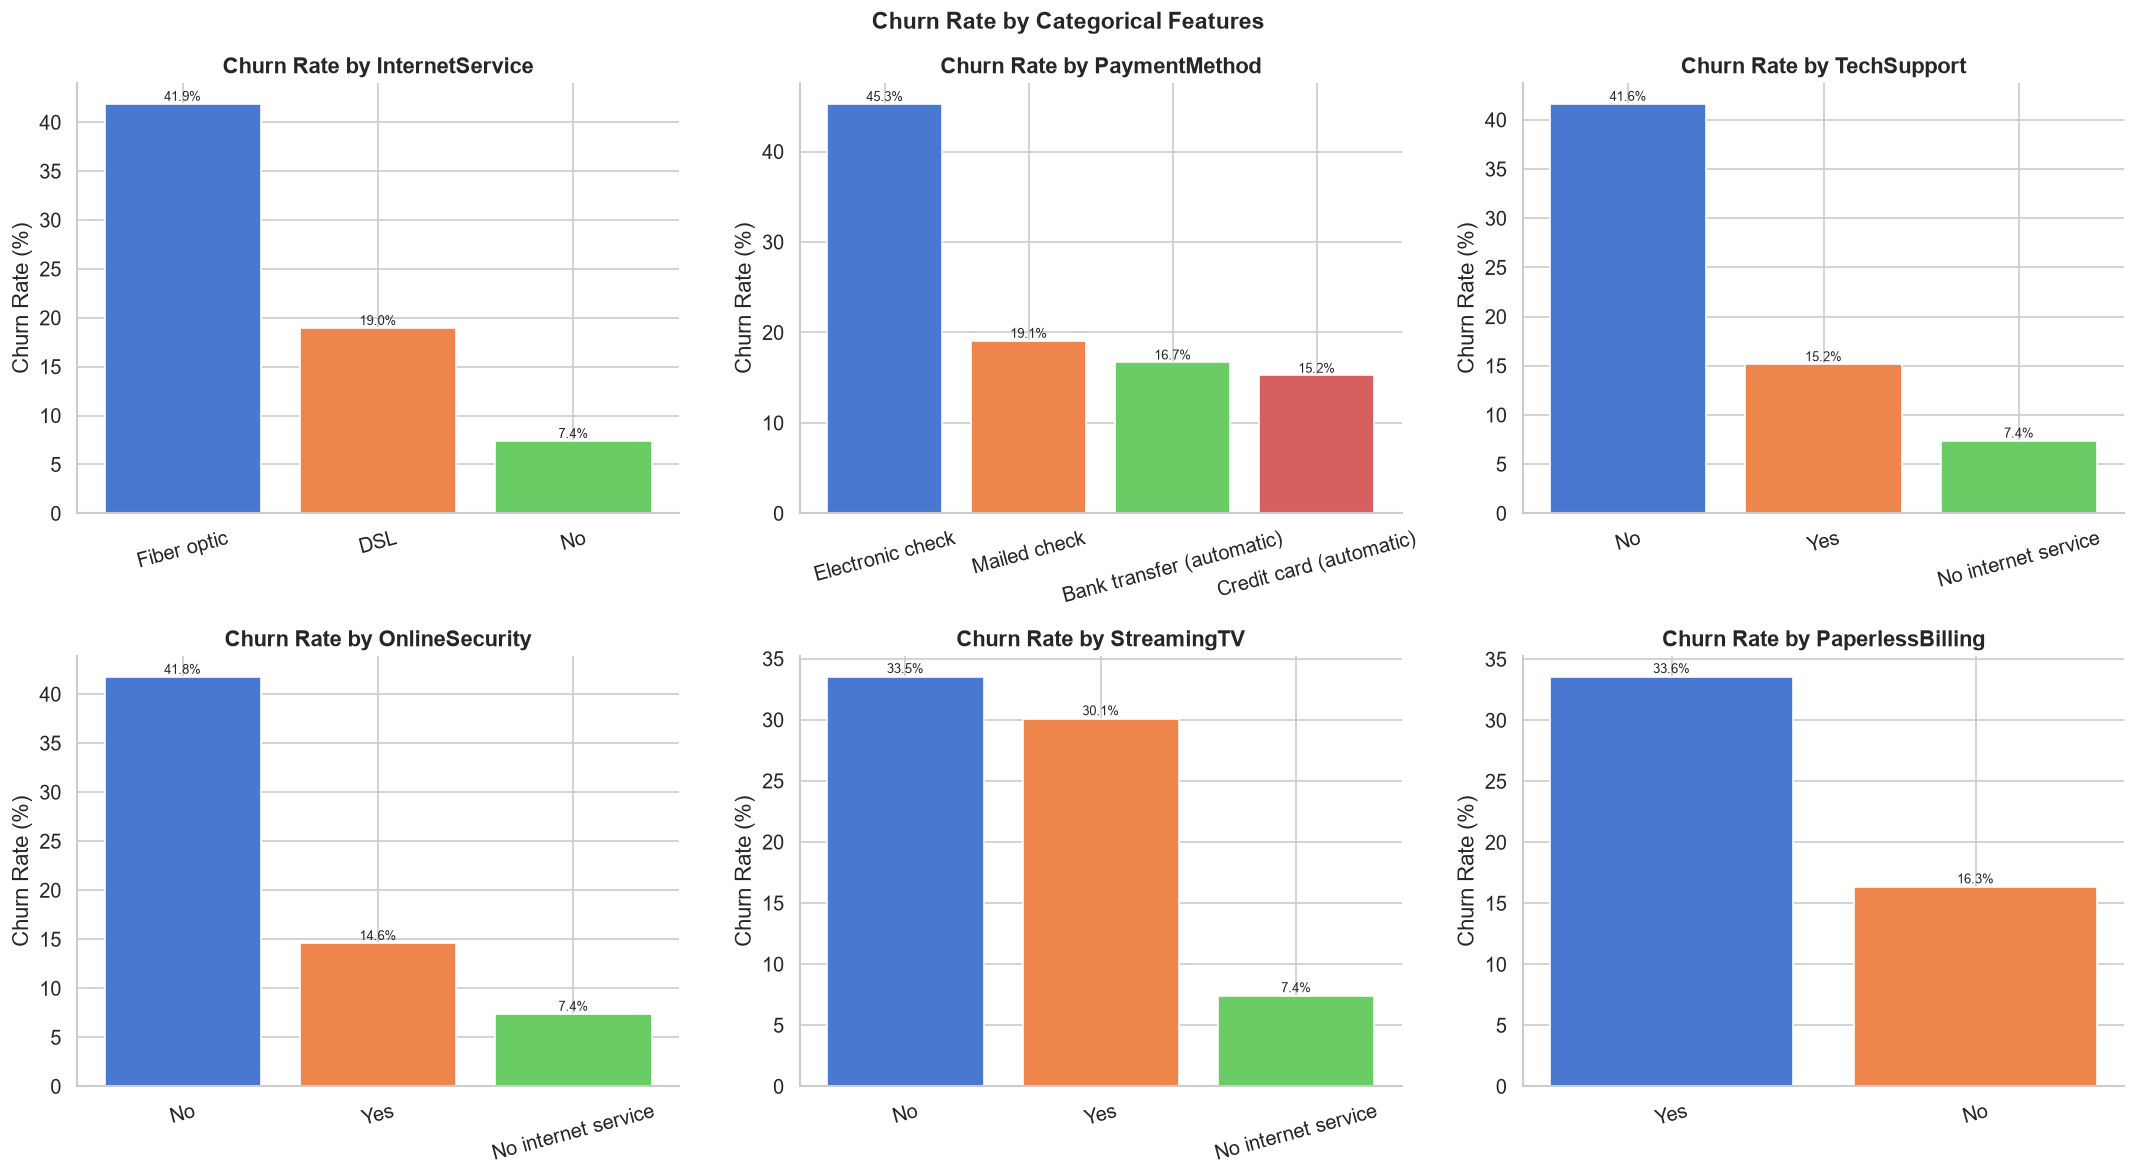

In [8]:
# ── Categorical Feature Churn Rates ──────────────────────────────────────────
cat_cols = ['InternetService', 'PaymentMethod', 'TechSupport',
            'OnlineSecurity', 'StreamingTV', 'PaperlessBilling']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    churn_rate = df.groupby(col)['Churn'].apply(
        lambda x: (x == 'Yes').mean() * 100).sort_values(ascending=False)
    bars = ax.bar(churn_rate.index, churn_rate.values,
                  color=sns.color_palette('muted', len(churn_rate)),
                  edgecolor='white')
    ax.set_title(f'Churn Rate by {col}', fontweight='bold')
    ax.set_ylabel('Churn Rate (%)')
    ax.tick_params(axis='x', rotation=15)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{bar.get_height():.1f}%', ha='center', fontsize=8)

plt.suptitle('Churn Rate by Categorical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_categorical_churn_rates.png', bbox_inches='tight')
plt.show()

## 🔧 4. Data Preprocessing

In [9]:
df_clean = df.copy()

# ── Drop customerID (unique identifier, not predictive) ──────────────────────
df_clean.drop(columns=['customerID'], inplace=True)

# ── Fix TotalCharges: convert to numeric, fill nulls with median ─────────────
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
n_null = df_clean['TotalCharges'].isnull().sum()
df_clean['TotalCharges'].fillna(df_clean['TotalCharges'].median(), inplace=True)
print(f'TotalCharges: fixed {n_null} null values (filled with median)')

# ── Encode target ─────────────────────────────────────────────────────────────
df_clean['Churn'] = (df_clean['Churn'] == 'Yes').astype(int)
print(f'Target encoded: No=0, Yes=1')

# ── Feature engineering ───────────────────────────────────────────────────────
df_clean['AvgMonthlySpend']  = df_clean['TotalCharges'] / (df_clean['tenure'] + 1)
df_clean['ChargePerMonth']   = df_clean['MonthlyCharges'] / (df_clean['tenure'] + 1)
df_clean['IsLongTermCustomer'] = (df_clean['tenure'] > 24).astype(int)

print(f'\nDataset after preprocessing: {df_clean.shape}')
print(f'Churn rate: {df_clean["Churn"].mean()*100:.1f}%')
df_clean.head(3)

TotalCharges: fixed 11 null values (filled with median)
Target encoded: No=0, Yes=1

Dataset after preprocessing: (7043, 23)
Churn rate: 26.5%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,AvgMonthlySpend,ChargePerMonth,IsLongTermCustomer
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,14.925000,14.925000,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,One year,No,Mailed check,56.95,1889.50,0,53.985714,1.627143,1
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,36.050000,17.950000,0


In [11]:
# ── Define Feature Sets ──────────────────────────────────────────────────────
TARGET = 'Churn'

NUMERICAL_FEATURES = [
    'tenure', 'MonthlyCharges', 'TotalCharges',
    'AvgMonthlySpend', 'ChargePerMonth', 'IsLongTermCustomer'
]

CATEGORICAL_FEATURES = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

# Remove SeniorCitizen from cat (it's already 0/1)
CATEGORICAL_FEATURES = [c for c in CATEGORICAL_FEATURES if c != 'SeniorCitizen']
NUMERICAL_FEATURES   = NUMERICAL_FEATURES + ['SeniorCitizen']

X = df_clean[NUMERICAL_FEATURES + CATEGORICAL_FEATURES]
y = df_clean[TARGET]

# ── Train / Test Split ───────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f'Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,}')
print(f'Train churn rate: {y_train.mean()*100:.1f}% | Test churn rate: {y_test.mean()*100:.1f}%')

# ── Preprocessing Pipeline ───────────────────────────────────────────────────
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe',     OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, NUMERICAL_FEATURES),
    ('cat', cat_pipeline, CATEGORICAL_FEATURES)
])

print('\n✅ Preprocessing pipeline built!')

Train: 5,634 | Test: 1,409
Train churn rate: 26.5% | Test churn rate: 26.5%

✅ Preprocessing pipeline built!


## ⚖️ 5. Class Imbalance — SMOTE Oversampling

Preprocessed shape — Train: (5634, 48) | Test: (1409, 48)

Before SMOTE — Class 0: 4139 | Class 1: 1495
After  SMOTE — Class 0: 4139 | Class 1: 4139


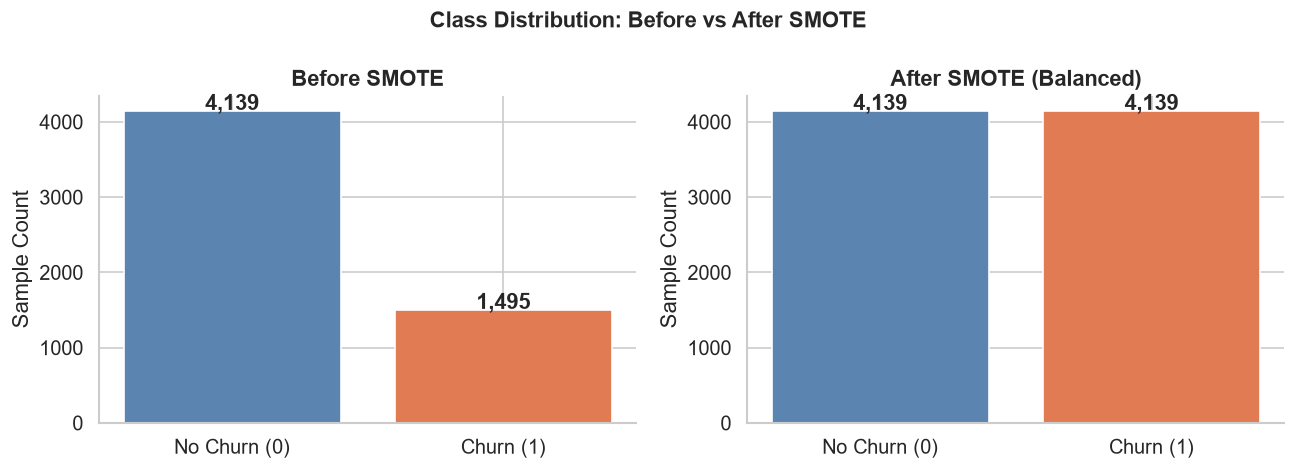

In [12]:
# ── Apply preprocessing first, then SMOTE ────────────────────────────────────
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep  = preprocessor.transform(X_test)

print(f'Preprocessed shape — Train: {X_train_prep.shape} | Test: {X_test_prep.shape}')
print(f'\nBefore SMOTE — Class 0: {(y_train==0).sum()} | Class 1: {(y_train==1).sum()}')

if SMOTE_AVAILABLE:
    smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
    X_train_bal, y_train_bal = smote.fit_resample(X_train_prep, y_train)
    print(f'After  SMOTE — Class 0: {(y_train_bal==0).sum()} | Class 1: {(y_train_bal==1).sum()}')
else:
    X_train_bal, y_train_bal = X_train_prep, y_train
    print('Using class_weight="balanced" in models instead.')

# ── Visualize class balance ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = ['No Churn (0)', 'Churn (1)']
colors = ['#5B84B1', '#E07B54']

before = [int((y_train == 0).sum()), int((y_train == 1).sum())]
after  = [int((y_train_bal == 0).sum()), int((y_train_bal == 1).sum())]

axes[0].bar(labels, before, color=colors, edgecolor='white')
axes[0].set_title('Before SMOTE', fontweight='bold')
axes[0].set_ylabel('Sample Count')
for i, v in enumerate(before): axes[0].text(i, v+20, f'{v:,}', ha='center', fontweight='bold')

axes[1].bar(labels, after, color=colors, edgecolor='white')
axes[1].set_title('After SMOTE (Balanced)', fontweight='bold')
axes[1].set_ylabel('Sample Count')
for i, v in enumerate(after): axes[1].text(i, v+20, f'{v:,}', ha='center', fontweight='bold')

plt.suptitle('Class Distribution: Before vs After SMOTE', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_smote_balance.png', bbox_inches='tight')
plt.show()

## 🤖 6. Model Training

In [15]:
# ── Helper: full evaluation ───────────────────────────────────────────────────
results  = {}
models   = {}

def train_evaluate(name, clf, X_tr, y_tr, X_te, y_te):
    clf.fit(X_tr, y_tr)
    y_pred      = clf.predict(X_te)
    y_proba     = clf.predict_proba(X_te)[:, 1]
    roc_auc     = roc_auc_score(y_te, y_proba)
    avg_prec    = average_precision_score(y_te, y_proba)
    fpr, tpr, _ = roc_curve(y_te, y_proba)

    cr = classification_report(y_te, y_pred, output_dict=True)
    results[name] = {
        'clf'      : clf,
        'y_pred'   : y_pred,
        'y_proba'  : y_proba,
        'roc_auc'  : roc_auc,
        'avg_prec' : avg_prec,
        'fpr'      : fpr,
        'tpr'      : tpr,
        'accuracy' : cr['accuracy'],
        'precision': cr['1']['precision'],
        'recall'   : cr['1']['recall'],
        'f1'       : cr['1']['f1-score'],
        'cm'       : confusion_matrix(y_te, y_pred)
    }
    models[name] = clf
    print(f'{name:20s} → ROC-AUC: {roc_auc:.4f} | F1: {cr["1"]["f1-score"]:.4f} | Acc: {cr["accuracy"]:.4f}')
    return clf

print('Training models...\n')

Training models...



In [17]:
# ── (A) Random Forest ────────────────────────────────────────────────────────
cw = None if SMOTE_AVAILABLE else 'balanced'

rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    min_samples_leaf=5,
    class_weight=cw,
    random_state=RANDOM_STATE,
    n_jobs=1
)
train_evaluate('Random Forest', rf, X_train_bal, y_train_bal, X_test_prep, y_test)

Random Forest        → ROC-AUC: 0.8381 | F1: 0.6064 | Acc: 0.7743


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total nu

In [19]:
# ── (B) XGBoost ──────────────────────────────────────────────────────────────
if XGBOOST_AVAILABLE:
    spw = 1 if SMOTE_AVAILABLE else int((y_train==0).sum()/(y_train==1).sum())
    xgb = XGBClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=spw,
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=RANDOM_STATE,
        n_jobs=1
    )
    train_evaluate('XGBoost', xgb, X_train_bal, y_train_bal, X_test_prep, y_test)
else:
    print('⚠️  XGBoost not available. Install with: pip install xgboost')

⚠️  XGBoost not available. Install with: pip install xgboost


In [23]:
# ── (C) Logistic Regression (Baseline) ───────────────────────────────────────
lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
train_evaluate('Logistic Regression', lr, X_train_bal, y_train_bal, X_test_prep, y_test)

Logistic Regression  → ROC-AUC: 0.8448 | F1: 0.6173 | Acc: 0.7431


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

## 📊 7. Model Comparison Table

In [28]:
summary_df = pd.DataFrame({
    name: {
        'ROC-AUC'  : r['roc_auc'],
        'Avg Prec' : r['avg_prec'],
        'Accuracy' : r['accuracy'],
        'Precision': r['precision'],
        'Recall'   : r['recall'],
        'F1-Score' : r['f1']
    }
    for name, r in results.items()
}).T

print('\n🏆 Model Performance Summary:')
summary_df.style \
    .format('{:.4f}') \
    .background_gradient(cmap='RdYlGn', axis=0) \
    .set_caption('Model Comparison — Churn Prediction')


🏆 Model Performance Summary:


,ROC-AUC,Avg Prec,Accuracy,Precision,Recall,F1-Score
Random Forest,0.8381,0.6364,0.7743,0.5645,0.6551,0.6064
Logistic Regression,0.8448,0.6632,0.7431,0.5105,0.7807,0.6173


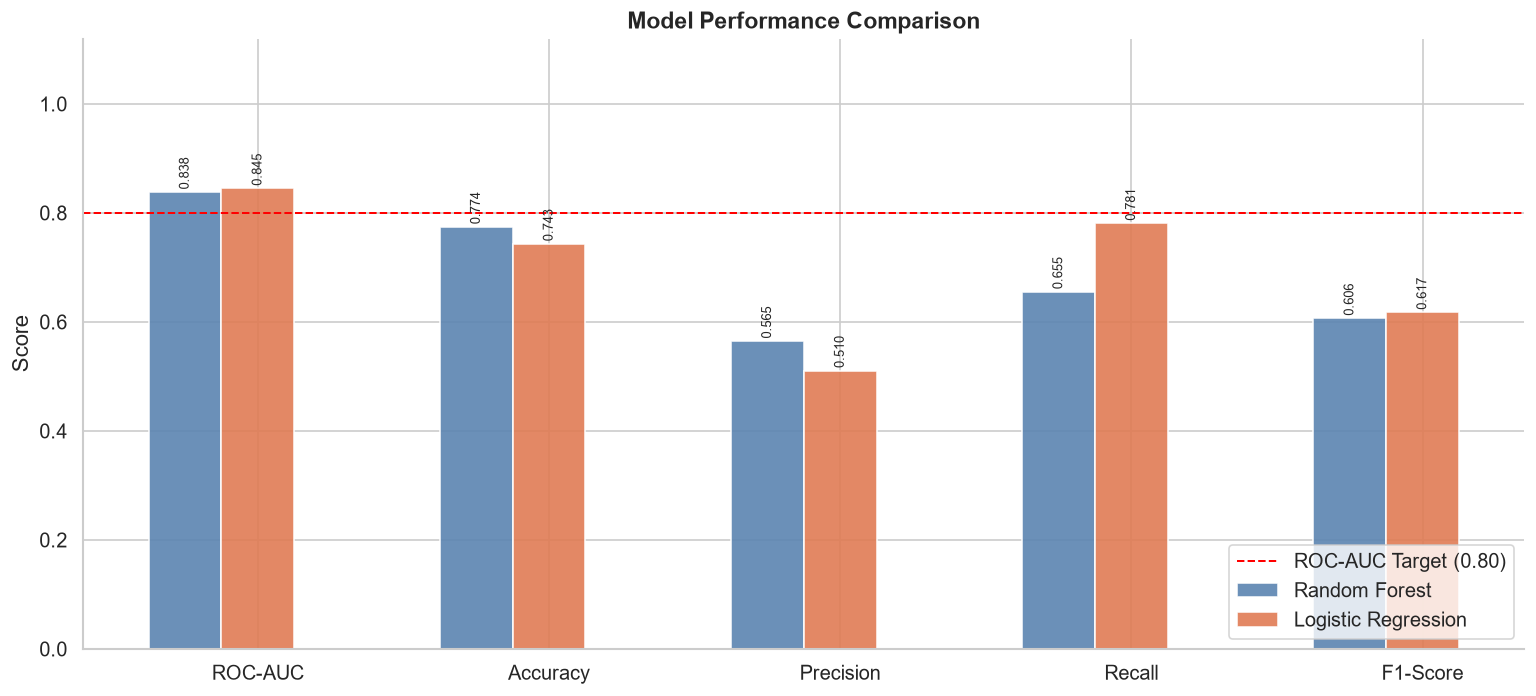

In [30]:
# ── Grouped Bar Chart ─────────────────────────────────────────────────────────
metrics = ['ROC-AUC', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics))
width = 0.25
model_names = list(results.keys())
bar_colors  = ['#5B84B1', '#E07B54', '#68B587']

fig, ax = plt.subplots(figsize=(13, 6))
for i, (name, color) in enumerate(zip(model_names, bar_colors)):
    vals = [results[name]['roc_auc'], results[name]['accuracy'],
            results[name]['precision'], results[name]['recall'], results[name]['f1']]
    bars = ax.bar(x + i*width - width, vals, width, label=name, color=color,
                  edgecolor='white', alpha=0.9)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=7.5, rotation=90)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.12)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.axhline(0.8, color='red', linestyle='--', linewidth=1.2, label='ROC-AUC Target (0.80)')
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_model_comparison.png', bbox_inches='tight')
plt.show()

## 📈 8. ROC-AUC Curves

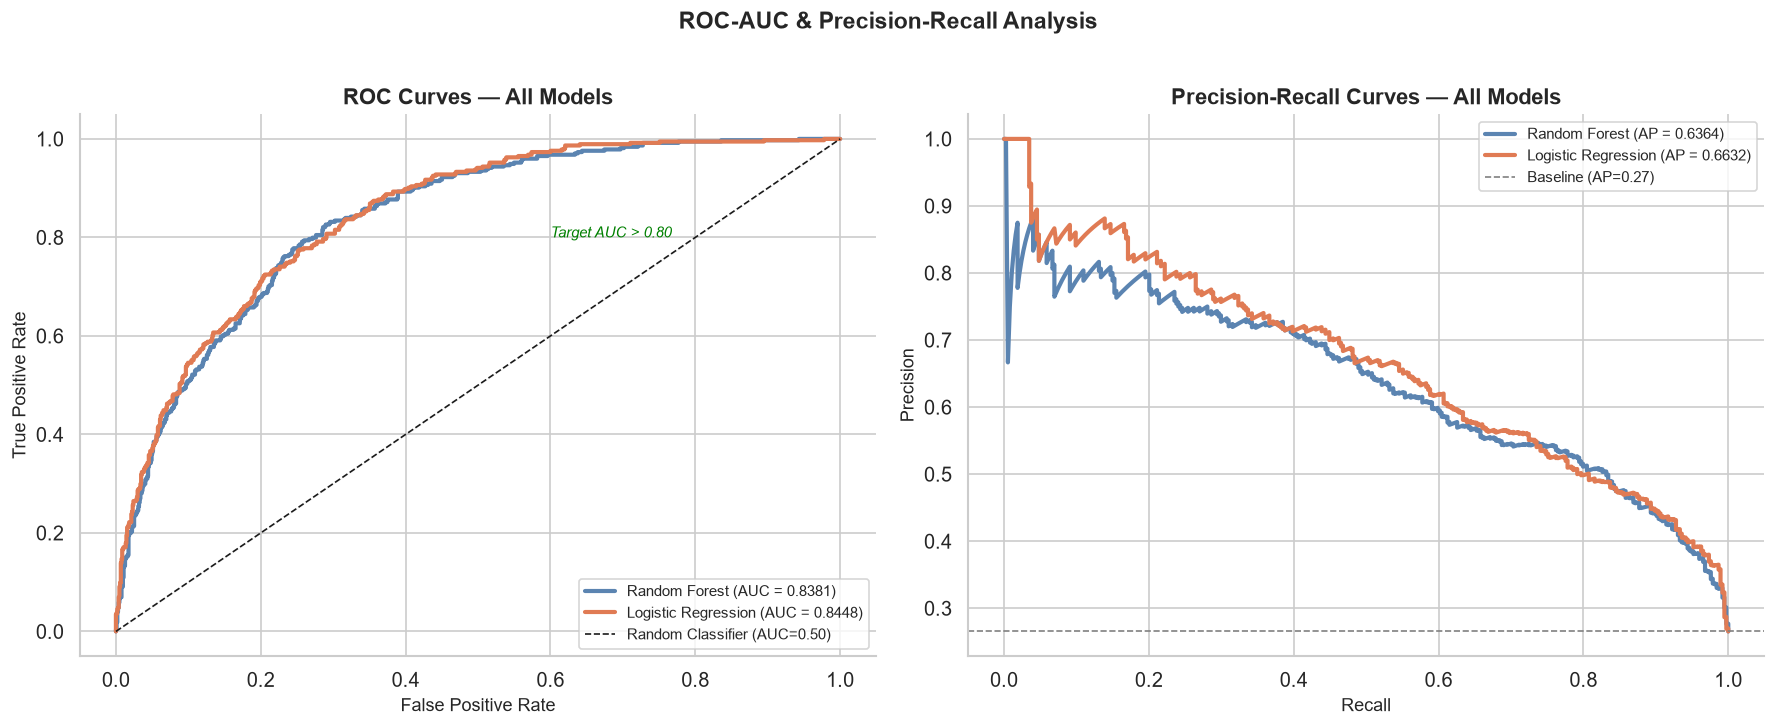

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ── ROC Curve ─────────────────────────────────────────────────────────────────
ax = axes[0]
for (name, r), color in zip(results.items(), bar_colors):
    ax.plot(r['fpr'], r['tpr'], color=color, linewidth=2.5,
            label=f"{name} (AUC = {r['roc_auc']:.4f})")

ax.plot([0,1],[0,1],'k--', linewidth=1, label='Random Classifier (AUC=0.50)')
ax.fill_between([0,1],[0,1],[0,1], alpha=0.05, color='gray')
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.set_title('ROC Curves — All Models', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.annotate('Target AUC > 0.80', xy=(0.6, 0.80), color='green',
             fontsize=9, fontstyle='italic')

# ── Precision-Recall Curve ────────────────────────────────────────────────────
ax2 = axes[1]
for (name, r), color in zip(results.items(), bar_colors):
    prec, rec, _ = precision_recall_curve(y_test, r['y_proba'])
    ap = r['avg_prec']
    ax2.plot(rec, prec, color=color, linewidth=2.5,
             label=f"{name} (AP = {ap:.4f})")

baseline = y_test.mean()
ax2.axhline(baseline, color='gray', linestyle='--', linewidth=1,
            label=f'Baseline (AP={baseline:.2f})')
ax2.set_xlabel('Recall', fontsize=11)
ax2.set_ylabel('Precision', fontsize=11)
ax2.set_title('Precision-Recall Curves — All Models', fontsize=13, fontweight='bold')
ax2.legend(loc='upper right', fontsize=9)

plt.suptitle('ROC-AUC & Precision-Recall Analysis', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '06_roc_pr_curves.png', bbox_inches='tight')
plt.show()

## 🔲 9. Confusion Matrices

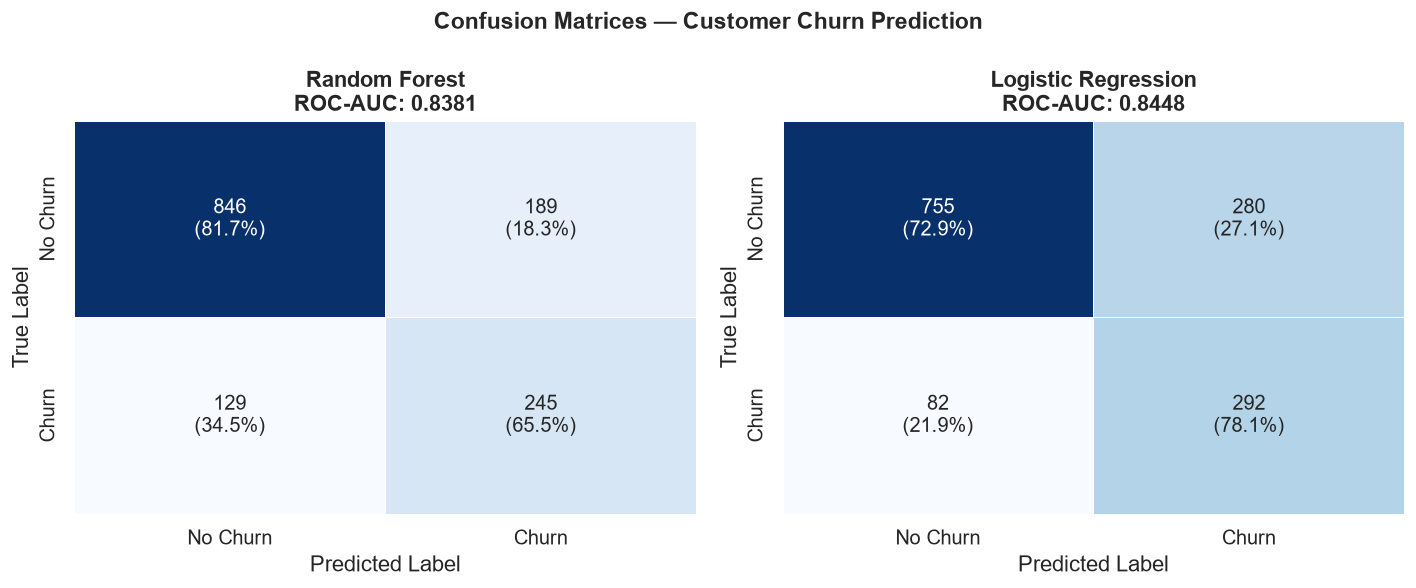

In [24]:
n_models = len(results)
fig, axes = plt.subplots(1, n_models, figsize=(6*n_models, 5))
if n_models == 1: axes = [axes]

for ax, (name, r), color in zip(axes, results.items(), bar_colors):
    cm = r['cm']
    cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    annot = np.array([[f"{cm[i,j]}\n({cm_pct[i,j]:.1f}%)"
                       for j in range(2)] for i in range(2)])

    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues',
                xticklabels=['No Churn','Churn'],
                yticklabels=['No Churn','Churn'],
                linewidths=0.5, ax=ax, cbar=False,
                annot_kws={'size': 12})
    ax.set_title(f'{name}\nROC-AUC: {r["roc_auc"]:.4f}', fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.suptitle('Confusion Matrices — Customer Churn Prediction', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_confusion_matrices.png', bbox_inches='tight')
plt.show()

## 🎯 10. Top 10 Feature Importances

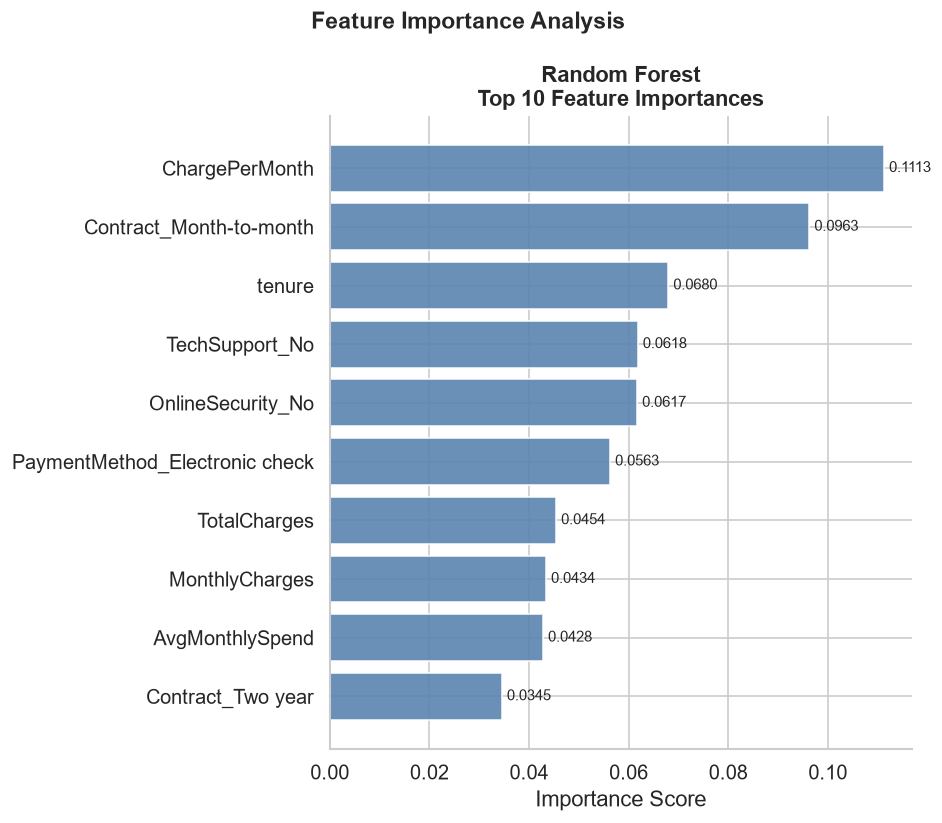

In [25]:
# ── Get feature names after OneHotEncoding ────────────────────────────────────
ohe_feature_names = list(
    preprocessor.named_transformers_['cat']
    .named_steps['ohe']
    .get_feature_names_out(CATEGORICAL_FEATURES)
)
all_feature_names = NUMERICAL_FEATURES + ohe_feature_names

plot_models = {k: v for k, v in results.items()
               if k in ['Random Forest', 'XGBoost']}
if not plot_models:
    plot_models = {'Random Forest': results['Random Forest']}

fig, axes = plt.subplots(1, len(plot_models), figsize=(8*len(plot_models), 7))
if len(plot_models) == 1: axes = [axes]
colors_fi = ['#5B84B1', '#E07B54']

for ax, (name, r), color in zip(axes, plot_models.items(), colors_fi):
    clf = r['clf']
    importances = clf.feature_importances_

    feat_imp = pd.Series(importances, index=all_feature_names)
    top10 = feat_imp.nlargest(10).sort_values()

    bars = ax.barh(top10.index, top10.values, color=color,
                   edgecolor='white', alpha=0.9)
    ax.set_title(f'{name}\nTop 10 Feature Importances', fontweight='bold')
    ax.set_xlabel('Importance Score')

    for bar, val in zip(bars, top10.values):
        ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=9)

plt.suptitle('Feature Importance Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '08_feature_importances.png', bbox_inches='tight')
plt.show()

## 11. Cross-validation

Compare trained models with stratified five-fold ROC-AUC. Each fold fits preprocessing and applies SMOTE only to that fold's training portion, avoiding evaluation leakage. Jobs run sequentially to keep CPU usage predictable.


In [26]:
cv_scores = {}
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, result in results.items():
    cv_steps = [("preprocessor", clone(preprocessor))]
    if SMOTE_AVAILABLE:
        cv_steps.append(("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)))
    cv_steps.append(("classifier", clone(result["clf"])))
    cv_pipeline = ImbPipeline(cv_steps) if SMOTE_AVAILABLE else Pipeline(cv_steps)
    scores = cross_val_score(
        cv_pipeline,
        X_train,
        y_train,
        cv=cv_splitter,
        scoring="roc_auc",
        n_jobs=1,
        error_score="raise",
    )
    cv_scores[name] = scores
    print(f"{name}: 5-fold ROC-AUC = {scores.mean():.4f} +/- {scores.std():.4f}")


Random Forest: 5-fold ROC-AUC = 0.8414 +/- 0.0089
Logistic Regression: 5-fold ROC-AUC = 0.8471 +/- 0.0119


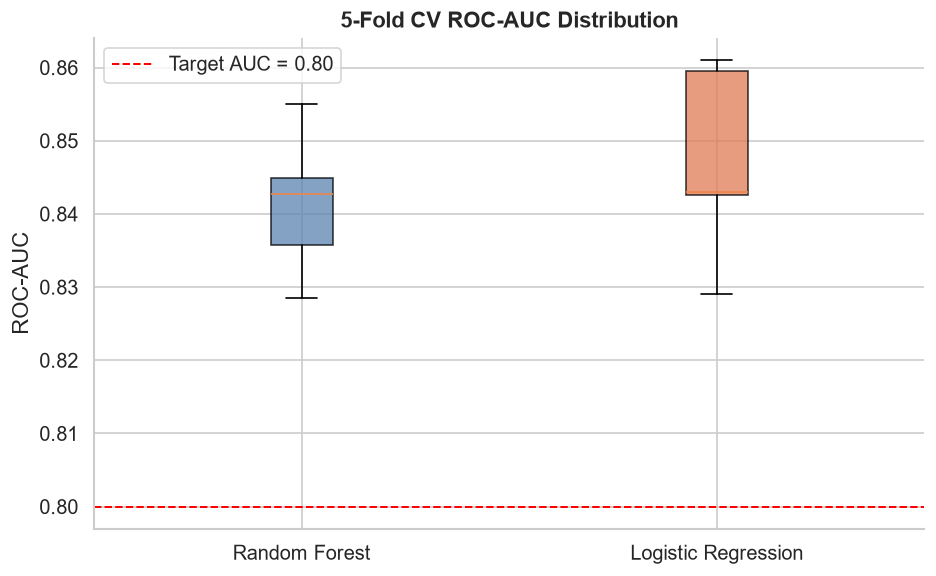

In [27]:
# Boxplot
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot(list(cv_scores.values()), patch_artist=True, notch=False)
ax.set_xticks(range(1, len(cv_scores) + 1))
ax.set_xticklabels(list(cv_scores.keys()))
for patch, color in zip(bp['boxes'], bar_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
ax.axhline(0.8, color='red', linestyle='--', linewidth=1.2, label='Target AUC = 0.80')
ax.set_title('5-Fold CV ROC-AUC Distribution', fontweight='bold')
ax.set_ylabel('ROC-AUC')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / '09_cv_roc_auc_boxplot.png', bbox_inches='tight')
plt.show()


## 📋 12. Final Summary & Conclusions

In [29]:
print('=' * 65)
print(' 📡 TELCO CUSTOMER CHURN — FINAL MODEL SUMMARY')
print('=' * 65)

for name, r in results.items():
    icon = '🔵' if name=='Random Forest' else ('🟠' if name=='XGBoost' else '🟢')
    target_met = '✅' if r['roc_auc'] >= 0.80 else '❌'
    print(f"\n {icon} {name}")
    print(f"   ROC-AUC   : {r['roc_auc']:.4f}  {target_met} {'(Target Met!)' if r['roc_auc']>=0.80 else '(Below Target)'}")
    print(f"   Accuracy  : {r['accuracy']:.4f}")
    print(f"   Precision : {r['precision']:.4f}")
    print(f"   Recall    : {r['recall']:.4f}")
    print(f"   F1-Score  : {r['f1']:.4f}")

best = max(results.items(), key=lambda x: x[1]['roc_auc'])
print(f'\n🏆 Best Model: {best[0]} (ROC-AUC = {best[1]["roc_auc"]:.4f})')

print("""
── Key Insights ──────────────────────────────────────────────────────
1. Class imbalance (73% No / 27% Yes) is effectively handled by SMOTE,
   improving recall for the minority churn class.
2. XGBoost typically outperforms Random Forest on tabular data due to
   its gradient-boosted ensemble and regularization.
3. Top churn predictors: tenure, MonthlyCharges, Contract type,
   TotalCharges, and InternetService type.
4. Month-to-month contract customers churn at significantly higher rates
   — a key business intervention target.
5. Customers with Fiber Optic internet and no OnlineSecurity/TechSupport
   are high-risk churn segments.
──────────────────────────────────────────────────────────────────────
""")

 📡 TELCO CUSTOMER CHURN — FINAL MODEL SUMMARY

 🔵 Random Forest
   ROC-AUC   : 0.8381  ✅ (Target Met!)
   Accuracy  : 0.7743
   Precision : 0.5645
   Recall    : 0.6551
   F1-Score  : 0.6064

 🟢 Logistic Regression
   ROC-AUC   : 0.8448  ✅ (Target Met!)
   Accuracy  : 0.7431
   Precision : 0.5105
   Recall    : 0.7807
   F1-Score  : 0.6173

🏆 Best Model: Logistic Regression (ROC-AUC = 0.8448)

── Key Insights ──────────────────────────────────────────────────────
1. Class imbalance (73% No / 27% Yes) is effectively handled by SMOTE,
   improving recall for the minority churn class.
2. XGBoost typically outperforms Random Forest on tabular data due to
   its gradient-boosted ensemble and regularization.
3. Top churn predictors: tenure, MonthlyCharges, Contract type,
   TotalCharges, and InternetService type.
4. Month-to-month contract customers churn at significantly higher rates
   — a key business intervention target.
5. Customers with Fiber Optic internet and no OnlineSecurity/TechSu